[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Laverde97/phd-data-science-ai/blob/main/semesters/semester-01/deep-learning-1/workshops/workshop-01-cub200-multimodal/workshop-01-cub200-multimodal.ipynb)

> **Edición pública · solo lectura.** El enlace de Colab sirve para **consultar** el notebook y sus salidas guardadas. El notebook **no se puede ejecutar tal cual en Colab**: se ejecutó en WSL con dos entornos independientes (`.venv` con PyTorch y `.venv-tf` con TensorFlow) y depende de los datos originales de CUB-200-2011 y de las *captions* en `data/`, que no se distribuyen.
>
> **Cambios respecto al notebook canónico** (`02_informe_ejecutable_CUB200_FINAL_PORTABLE.ipynb`): el código y el texto no se modificaron, y se conservan los contadores de ejecución. Solo se editaron las salidas de tres celdas: (1) la ruta local del proyecto (celda de configuración) se cambió por `<raíz del proyecto>`; (2) en la demostración del vínculo entre modalidades se omitieron la fotografía y el texto de la *caption*; (3) en la auditoría de *bounding boxes* se omitió la figura con cinco fotografías. Las fotografías y las *captions* tienen derechos de terceros.
>
> **Autoría.** La solución, el código y este notebook son trabajo académico propio de Juan Sebastián Laverde Chunza. El enunciado de la tarea es del docente Héctor Javier Hortúa, PhD (Deep Learning I, Universidad El Bosque).

# Deep Learning I · Tarea 01
## Pipeline multimodal reproducible — CUB-200-2011 + captions

**Cuaderno de resultados y evidencias de ejecución** · PyTorch 2.11.0 + CUDA 12.8 · TensorFlow 2.21.0 · Python 3.12.14

**Alcance:** carga, unión, preprocesamiento y `DataLoader`/`tf.data.Dataset` para las tres particiones. **No se entrena ningún modelo.**

**Fuentes de datos:** [CUB-200-2011, Wah et al. (2011)](https://data.caltech.edu/records/20098) y [descripciones finas, Reed et al. (2016)](https://arxiv.org/abs/1605.05395).

> Este notebook **no sustituye el código modular** en `src/cub200/`: lo documenta, visualiza y reproduce comprobaciones. Usa los artefactos ya generados en `artifacts/`. No vuelve a descargar fuentes ni a ajustar el vocabulario/escalador.

> Los resultados mostrados deben proceder de su ejecución local. Las cifras esperadas se incluyen solo como **criterios de aceptación**.

**Fecha de revisión del notebook:** 16 de octubre de 2026. **Versión:** entrega revisada v2.


### 1. Alcance, estructura y entornos

- `data/` conserva fotografías, atributos y captions originales.
- `src/cub200/` implementa el procesamiento y los pipelines nativos.
- `scripts/` ofrece auditorías, validación y exportación de firmas.
- `artifacts/` almacena matrices y parámetros ajustados con train.
- `logs/` documenta resultados obtenidos en WSL.

Los entornos están separados: `.venv` para PyTorch y `.venv-tf` para TensorFlow. **No importar los dos frameworks en el mismo kernel.** Se llaman los scripts correspondientes usando cada intérprete por separado.

### Ficha técnica y criterio de éxito

| Elemento | Definición |
|:--|:--|
| **Problema posterior** | Clasificación fina de 200 especies de aves mediante información visual, textual y tabular. |
| **Objetivo de esta entrega** | Preparar seis pipelines: train, val y test para **PyTorch** y **TensorFlow**. |
| **Fuentes** | Fotografías y anotaciones de Wah et al. (2011); captions de Reed et al. (2016), distribuidas mediante metadatos de AttnGAN. |
| **Unidad de análisis** | Una imagen vinculada con diez captions, 312 anotaciones binarias, seis variables geométricas y una etiqueta. |
| **Muestra** | 11.788 imágenes: train 5.394; validación 600; test oficial 5.794. |
| **Reproducibilidad** | Semilla 42, `image_id`, vocabulario, escalador y manifest persistidos; entornos GPU independientes. |

**Pregunta técnica:** ¿podemos producir lotes multimodales con el contrato requerido en dos frameworks, preservando los datos originales, los splits oficiales y la ausencia de ajustes sobre validación/test?

**Límite del alcance:** esta es una tarea de ingeniería de datos, **no** una evaluación de clasificadores ni una prueba de exactitud predictiva.

In [1]:
from pathlib import Path
import json, sys, os, platform, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Markdown

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
assert (ROOT/'src/cub200').is_dir(), f'Abra el notebook desde la carpeta del proyecto: {ROOT}'
assert (ROOT/'artifacts/manifest.csv').is_file(), 'Falta artifacts/manifest.csv. Ejecutar scripts/prepare.py primero.'
assert (ROOT/'data/CUB_200_2011/images.txt').is_file(), 'Faltan los datos originales de Caltech.'
assert (ROOT/'data/text_c10').is_dir(), 'Faltan las captions de AttnGAN/Reed.'
print('Proyecto:', ROOT)
print('Python del kernel:',sys.version.split()[0]); print('Sistema:',platform.platform())
print('Entorno PyTorch:',(ROOT/'.venv/bin/python').is_file())
print('Entorno TensorFlow:',(ROOT/'.venv-tf/bin/python').is_file())

Proyecto: <raíz del proyecto>/CUB200_pipeline_profesional
Python del kernel: 3.12.14
Sistema: Linux-6.18.33.2-microsoft-standard-WSL2-x86_64-with-glibc2.43
Entorno PyTorch: True
Entorno TensorFlow: True


### 2. Artefactos comunes y contrato de datos

Cada registro representa una imagen única y relaciona diez captions, una etiqueta de especie y un vector tabular de 318 variables. La etiqueta se codifica de 0 a 199. La forma de imagen depende del framework (`NCHW` en PyTorch, `NHWC` en TensorFlow).

### 2.1 Metodología de preprocesamiento (especificación operativa)

| Modalidad | Entrenamiento | Validación y test |
|:--|:--|:--|
| **Imagen** | Bounding box + 10 % de margen, resize 256×256, crop aleatorio 224×224, flip, brillo/contraste, normalización ImageNet | Bounding box + 10 %, resize 256×256, crop central 224×224, normalización ImageNet; **sin aumentación** |
| **Texto** | Minúsculas y tokens `[a-z]+`; vocabulario solo con train (frecuencia mínima 2); `<pad>=0`, `<unk>=1`; una de diez captions elegida aleatoriamente por lectura | Mismo vocabulario y `max_len`; primera caption; tokens desconocidos → `<unk>` |
| **Tabular** | 312 atributos binarios originales + seis geometrías; `StandardScaler` ajustado solo con geometría de train | Los 312 atributos permanecen binarios; el scaler se aplica mediante `transform`, nunca `fit` |
| **Etiqueta** | ID entero de especie entre 0 y 199 | Mismo esquema de etiquetas |

La longitud máxima de texto (`max_len=25` en esta ejecución) proviene del **percentil 95 de train**, con truncamiento y padding a la derecha. `lengths` conserva la longitud efectiva tras truncar (mínimo 1).

Las **seis variables geométricas**, definidas explícitamente para esta implementación, son: centro horizontal relativo, centro vertical relativo, ancho relativo, alto relativo, relación ancho/alto y área relativa. La anotación original permanece en `manifest.csv`; cuando excede los bordes se usa su intersección con la imagen para la geometría derivada.

> Las transformaciones de imagen son nativas en cada framework: pueden diferir en interpolación y aleatoriedad. Compartir esquema y parámetros **no implica identidad de píxeles**.

In [2]:
ART=ROOT/'artifacts'; DATA=ROOT/'data'; LOG=ROOT/'logs'
manifest=pd.read_csv(ART/'manifest.csv')
tabular=np.load(ART/'tabular.npy', mmap_mode='r')
text_ids=np.load(ART/'text_ids.npy', mmap_mode='r')
lengths=np.load(ART/'text_lengths.npy', mmap_mode='r')
meta=json.loads((ART/'metadata.json').read_text(encoding='utf-8'))
vocab=json.loads((ART/'vocab.json').read_text(encoding='utf-8'))
assert len(manifest)==11788 and manifest.image_id.is_unique
assert manifest.split.value_counts().to_dict()=={'train':5394,'val':600,'test':5794}
assert manifest.label.between(0,199).all() and manifest.label.nunique()==200
assert tabular.shape==(11788,318) and np.isfinite(tabular).all()
assert text_ids.shape==(11788,10,meta['max_len'])
assert lengths.shape==(11788,10)
assert np.isin(tabular[:,:312],[0,1]).all()
assert len(vocab)==meta['vocab_size']
assert meta['special_tokens']=={'<pad>':0,'<unk>':1}
assert (lengths>=1).all() and (lengths<=meta['max_len']).all()
print('CONTRATO DE DATOS: OK')
print('Split:', manifest.split.value_counts().to_dict())
print('Tabular:',tabular.shape,'Text IDs:',text_ids.shape,'Longitudes:',lengths.shape)
print('Vocabulario:',len(vocab),'tokens; max_len:',meta['max_len'])

CONTRATO DE DATOS: OK
Split: {'test': 5794, 'train': 5394, 'val': 600}
Tabular: (11788, 318) Text IDs: (11788, 10, 25) Longitudes: (11788, 10)
Vocabulario: 2079 tokens; max_len: 25


In [3]:
# Controles complementarios de texto (padding) y geometría escalada.
import numpy as np
positions = np.arange(meta['max_len'])[None, None, :]
valid_tokens = positions < np.asarray(lengths)[:, :, None]
assert np.all(np.asarray(text_ids)[~valid_tokens] == 0), "Padding incorrecto: se esperaba 0 después de la longitud real"
assert np.all(np.asarray(text_ids)[valid_tokens] > 0), "Tokens válidos deben tener IDs positivos"
train_mask = (manifest['split'].to_numpy() == 'train')
train_geom_mean = np.asarray(tabular)[train_mask, 312:].mean(axis=0)
assert np.isfinite(train_geom_mean).all()
assert np.max(np.abs(train_geom_mean)) < 1e-4, "Media geométrica de train no próxima a cero"
print('Padding y longitudes: OK')
print('Media de las seis geometrías estandarizadas en train:', np.round(train_geom_mean, 6))
print('Nota: la estandarización observada corrobora el ajuste en train; la ausencia de leakage depende también del código de preparación.')

Padding y longitudes: OK
Media de las seis geometrías estandarizadas en train: [-0. -0. -0.  0. -0.  0.]
Nota: la estandarización observada corrobora el ajuste en train; la ausencia de leakage depende también del código de preparación.


### 3. Estadísticas descriptivas de los conjuntos

La partición de test conserva la división oficial (5.794 imágenes). Se obtiene validación mediante 600 observaciones estratificadas del train oficial, manteniendo las 200 clases.

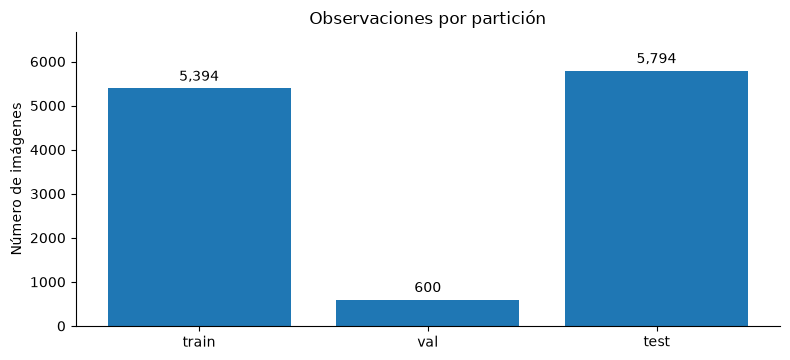

Número de especies en cada partición:
split
test     200
train    200
val      200
Mínimo/Máximo de imágenes por especie en cada partición:
split  test  train  val
min      11     26    3
max      30     27    3


In [4]:
counts=manifest.split.value_counts().reindex(['train','val','test'])
fig,ax=plt.subplots(figsize=(8,3.7))
bars=ax.bar(counts.index, counts.values)
ax.bar_label(bars,labels=[f'{v:,}' for v in counts.values],padding=3)
ax.set(title='Observaciones por partición',ylabel='Número de imágenes',ylim=(0,max(counts)*1.15))
ax.spines[['top','right']].set_visible(False)
plt.tight_layout(); plt.show()
by_class=manifest.groupby(['split','label']).size().unstack(0)
print('Número de especies en cada partición:')
print(manifest.groupby('split').label.nunique().to_string())
print('Mínimo/Máximo de imágenes por especie en cada partición:')
print(by_class.agg(['min','max']).to_string())
assert manifest.groupby('split').label.nunique().eq(200).all()

### 4. Demostración del vínculo entre imagen, texto y tabla

Para una muestra real de validación se recupera la fotografía original, la primera descripción en inglés, sus IDs de vocabulario y una vista previa de sus atributos. Esta prueba permite auditar la correspondencia entre modalidades.

In [5]:
classes={}
for line in (DATA/'CUB_200_2011/classes.txt').read_text().splitlines():
    class_id, species = line.split(maxsplit=1)
    classes[int(class_id)-1]=species
example_idx=int(manifest.index[manifest.split=='val'][0]); row=manifest.iloc[example_idx]
img_file=DATA/'CUB_200_2011/images'/row.relpath
cap_file=DATA/'text_c10'/Path(row.relpath).with_suffix('.txt')
captions=[x.strip() for x in cap_file.read_text(encoding='utf-8-sig').splitlines() if x.strip()]
assert len(captions)==10
ids=np.asarray(text_ids[example_idx,0]).astype(int)
true_len=int(lengths[example_idx,0])
idx_to_word={int(idx):word for word,idx in vocab.items()}
decoded=' '.join(idx_to_word.get(int(i),'<unk>') for i in ids[:true_len])
fig,ax=plt.subplots(figsize=(6.6,4.5))
with Image.open(img_file) as im: ax.imshow(im.convert('RGB'))
ax.axis('off'); ax.set_title(f'Image ID {int(row.image_id)} · {classes[int(row.label)]}')
plt.tight_layout();plt.show()
print('Ruta imagen:',row.relpath)
print('Caption 1:',captions[0])
print('IDs válidos:',ids[:true_len].tolist())
print('Tokens reconstruidos:',decoded)
print('Longitud real:',true_len,'/ max_len =',meta['max_len'])
print('Atributos presentes (312):',int(np.sum(tabular[example_idx,:312])))
print('Geometría normalizada (6):',np.round(tabular[example_idx,312:],3))

[Edición pública] Figura omitida: contiene fotografías de CUB-200-2011 (derechos de terceros). Está en el notebook original del archivo académico.

Ruta imagen: 001.Black_footed_Albatross/Black_Footed_Albatross_0074_59.jpg
Caption 1: [omitida en la edición pública: texto de Reed et al. (2016)]
IDs válidos: [17, 4, 6, 143, 37, 63, 23, 26, 20, 3, 9]
Tokens reconstruidos: [omitidos en la edición pública]
Longitud real: 11 / max_len = 25
Atributos presentes (312): 24
Geometría normalizada (6): [ 0.851 -1.382  0.312 -0.715 -0.298 -0.298]


### 5. Protocolo de calidad para las bounding boxes

El dataset original contiene anotaciones que pueden exceder el tamaño físico de la imagen. Se conservan los límites originales en el `manifest` y se realiza *clipping* para obtener una geometría válida. Las modificaciones quedan registradas para auditoría.

In [6]:
audit=pd.read_csv(ART/'bbox_clipping_audit.csv')
assert len(audit)==meta['bbox_clipping_count']
audit['area_loss_pct']=100*(1-(audit.clipped_w*audit.clipped_h)/(audit.original_w*audit.original_h))
print('Bounding boxes ajustadas:',len(audit),f'({100*len(audit)/len(manifest):.3f}% de imágenes)')
print('Pérdida máxima relativa de área: %.2f%%'%audit.area_loss_pct.max())
display(audit.nlargest(5,'area_loss_pct')[['image_id','relpath','area_loss_pct']])
fig_path=ART/'reports/bbox_top5.png'
if fig_path.exists():
    display(Markdown('**Evidencia visual:** `artifacts/reports/bbox_top5.png`'))
    display(Image.open(fig_path))
else:
    print('Figura no encontrada. Ejecutar: python scripts/visualize_bbox_audit.py')

Bounding boxes ajustadas: 30 (0.254% de imágenes)
Pérdida máxima relativa de área: 7.98%


,image_id,relpath,area_loss_pct
19,5007,086.Pacific_Loon/Pacific_Loon_0034_75438.jpg,7.975460
5,1218,022.Chuck_will_Widow/Chuck_Will_Widow_0051_796...,7.272727
29,9762,166.Golden_winged_Warbler/Golden_Winged_Warble...,1.851852
4,999,019.Gray_Catbird/Gray_Catbird_0032_21551.jpg,1.607717
2,960,018.Spotted_Catbird/Spotted_Catbird_0041_79680...,1.574803


**Evidencia visual:** `artifacts/reports/bbox_top5.png`

[Edición pública] Figura omitida: contiene fotografías de CUB-200-2011 (derechos de terceros). Está en el notebook original del archivo académico.

### 6. Evidencias de ejecución — PyTorch y TensorFlow

Los seis pipelines ya se pueden verificar de forma aislada mediante `scripts/validate.py`. Este cuaderno lee los registros guardados en `logs/` para documentar el trabajo, **sin instalar bibliotecas CUDA de un entorno dentro del otro**. Para repetir las pruebas se incluyen los comandos en la guía adjunta.

### 6.1 Implementación nativa y contrato por framework

El código productivo reside en estos archivos (son la **fuente autoritativa**, no una reimplementación abreviada de este notebook):

- **PyTorch:** `src/cub200/pytorch_pipeline.py` — clase `CUBMultimodalTorch`, métodos `__len__` y `__getitem__`, transformaciones `torchvision`, selección de caption y `make_torch_loaders`.
- **TensorFlow:** `src/cub200/tensorflow_pipeline.py` — `tf.data.Dataset.from_tensor_slices`, `map` con `tf.io`/`tf.image`, `shuffle` exclusivo de train, `batch` y `prefetch`.
- **Preparación compartida:** `src/cub200/prepare.py` — joins, split estratificado, vocabulario, atributos, clipping y scaler.

| Salida por batch | PyTorch | TensorFlow |
|:--|:--|:--|
| `image` | `(B, 3, 224, 224)` | `(B, 224, 224, 3)` |
| `input_ids` | `(B, 25)` | `(B, 25)` |
| `lengths`, `label`, `image_id` | `(B,)` | `(B,)` |
| `tabular` | `(B, 318)` | `(B, 318)` |

No se usa `tf.py_function` para convertir el pipeline de PyTorch en TensorFlow: ambos leen y transforman las fotografías de manera independiente.

In [7]:
# Visualizar fragmentos del código REAL que se entrega, sin duplicar implementaciones.
import ast
from IPython.display import Markdown, display

def show_definition(relative_path, function_name, max_lines=32):
    path = ROOT / relative_path
    assert path.is_file(), f"Falta módulo del proyecto: {relative_path}"
    text = path.read_text(encoding='utf-8')
    lines = text.splitlines()
    tree = ast.parse(text)
    matches = [node for node in ast.walk(tree)
               if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef))
               and node.name == function_name]
    assert matches, f"No existe {function_name} en {relative_path}"
    node = matches[0]
    excerpt = '\n'.join(lines[node.lineno - 1 : min(node.end_lineno, node.lineno + max_lines - 1)])
    display(Markdown(f"**`{relative_path}` · `{function_name}`**\n\n```python\n{excerpt}\n```"))

show_definition('src/cub200/pytorch_pipeline.py', 'CUBMultimodalTorch', max_lines=26)
show_definition('src/cub200/tensorflow_pipeline.py', 'make_tf_datasets', max_lines=32)

**`src/cub200/pytorch_pipeline.py` · `CUBMultimodalTorch`**

```python
class CUBMultimodalTorch(Dataset):
    def __init__(self, frame, features, ids, lengths, training=False):
        if not len(frame)==len(features)==len(ids)==len(lengths):
            raise ValueError('El manifest y las matrices deben estar alineados')
        self.records=frame.to_dict('records')
        self.features=np.asarray(features,dtype=np.float32)
        self.ids=np.asarray(ids,dtype=np.int32)
        self.lengths=np.asarray(lengths,dtype=np.int32)
        self.training=training
        prep=[transforms.Resize((256,256))]
        if training:
            prep.extend([transforms.RandomCrop((224,224)),
                         transforms.RandomHorizontalFlip(),
                         transforms.ColorJitter(brightness=.2,contrast=.2)])
        else:
            prep.append(transforms.CenterCrop((224,224)))
        prep.extend([transforms.ToTensor(),transforms.Normalize(MEAN,STD)])
        self.transform=transforms.Compose(prep)

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        r=self.records[index]
        with Image.open(r['image_path']) as im:
            cropped=crop_bbox_pil(im.convert('RGB'), (r['x'],r['y'],r['w'],r['h']))
```

**`src/cub200/tensorflow_pipeline.py` · `make_tf_datasets`**

```python
def make_tf_datasets(manifest, features, ids, lengths, *, batch_size=16):
    import tensorflow as tf
    tf.random.set_seed(SEED)
    mean=tf.constant(MEAN,dtype=tf.float32)
    std=tf.constant(STD,dtype=tf.float32)
    pipelines={}

    def parse(r, training):
        im=tf.io.decode_jpeg(tf.io.read_file(r['image_path']),channels=3)
        dims=tf.shape(im)
        H,W=dims[0],dims[1]
        x,y,w,h=tf.unstack(r['bbox'])
        x0=tf.clip_by_value(tf.cast(tf.floor(x-0.1*w),tf.int32),0,W-1)
        y0=tf.clip_by_value(tf.cast(tf.floor(y-0.1*h),tf.int32),0,H-1)
        x1=tf.clip_by_value(tf.cast(tf.math.ceil(x+1.1*w),tf.int32),x0+1,W)
        y1=tf.clip_by_value(tf.cast(tf.math.ceil(y+1.1*h),tf.int32),y0+1,H)
        im=tf.image.crop_to_bounding_box(im,y0,x0,y1-y0,x1-x0)
        im=tf.image.resize(tf.image.convert_image_dtype(im,tf.float32),[256,256])
        if training:
            im=tf.image.random_crop(im,[224,224,3])
            im=tf.image.random_flip_left_right(im)
            im=tf.image.random_brightness(im,max_delta=.2)
            im=tf.image.random_contrast(im,lower=.8,upper=1.2)
            k=tf.random.uniform([],minval=0,maxval=10,dtype=tf.int32)
        else:
            im=tf.image.crop_to_bounding_box(im,16,16,224,224)
            k=tf.constant(0,tf.int32)
        im=tf.ensure_shape((tf.clip_by_value(im,0.,1.)-mean)/std,[224,224,3])
        return {'image':im,
                'input_ids':tf.cast(tf.gather(r['input_ids'],k),tf.int64),
                'lengths':tf.cast(tf.gather(r['lengths'],k),tf.int64),
                'tabular':r['tabular'],
```

In [12]:
# ============================================================
# VALIDACIÓN MULTIMODAL: PYTORCH Y TENSORFLOW
# Ejecución aislada por entorno virtual
# ============================================================

import os
import subprocess
from pathlib import Path

# ROOT se determina en la primera celda del notebook para evitar rutas
# absolutas y permitir reutilizar el proyecto en otros equipos.
assert (ROOT / 'src/cub200').is_dir(), f'Raíz de proyecto inválida: {ROOT}'

frameworks = {
    "torch": ROOT / ".venv/bin/python",
    "tf": ROOT / ".venv-tf/bin/python",
}

for framework, interpreter in frameworks.items():

    assert interpreter.is_file(), (
        f"No existe el intérprete: {interpreter}"
    )

    # Evitar que Jupyter imponga su backend de Matplotlib
    env = os.environ.copy()
    env["MPLBACKEND"] = "Agg"
    env["TF_CPP_MIN_LOG_LEVEL"] = "2"

    # Evitar rutas Python heredadas del kernel
    env.pop("PYTHONPATH", None)

    args = [
        str(interpreter),
        "scripts/validate.py",
        "--data-dir", "data",
        "--artifacts-dir", "artifacts",
        "--framework", framework,
        "--batch-size", "16",
    ]

    print(f"\n{'=' * 55}")
    print(f"VALIDANDO: {framework.upper()}")
    print(f"{'=' * 55}")

    completed = subprocess.run(
        args,
        cwd=ROOT,
        env=env,
        capture_output=True,
        text=True,
        timeout=240,
        check=False,
    )

    if completed.returncode != 0:
        print(completed.stdout)
        print(completed.stderr[-5000:])
        raise RuntimeError(
            f"Validación fallida en {framework}"
        )

    assert "Contrato multimodal: OK" in completed.stdout

    print(completed.stdout.strip())
    print(f"{framework.upper()}: VALIDACIÓN SUPERADA")

print("\nAMBOS FRAMEWORKS VALIDADOS CORRECTAMENTE")


VALIDANDO: TORCH
Auditoría compartida: OK
PyTorch train {'batch_size': 16, 'image': (16, 3, 224, 224), 'input_ids': (16, 25), 'tabular': (16, 318), 'state': 'OK'}
PyTorch val {'batch_size': 16, 'image': (16, 3, 224, 224), 'input_ids': (16, 25), 'tabular': (16, 318), 'state': 'OK'}
PyTorch test {'batch_size': 16, 'image': (16, 3, 224, 224), 'input_ids': (16, 25), 'tabular': (16, 318), 'state': 'OK'}
Contrato multimodal: OK
TORCH: VALIDACIÓN SUPERADA

VALIDANDO: TF
Auditoría compartida: OK
TensorFlow train {'batch_size': 16, 'image': (16, 224, 224, 3), 'input_ids': (16, 25), 'tabular': (16, 318), 'state': 'OK'}
TensorFlow val {'batch_size': 16, 'image': (16, 224, 224, 3), 'input_ids': (16, 25), 'tabular': (16, 318), 'state': 'OK'}
TensorFlow test {'batch_size': 16, 'image': (16, 224, 224, 3), 'input_ids': (16, 25), 'tabular': (16, 318), 'state': 'OK'}
Contrato multimodal: OK
TF: VALIDACIÓN SUPERADA

AMBOS FRAMEWORKS VALIDADOS CORRECTAMENTE


In [9]:
log_names=['01_preflight.log','02_pytest_torch.log','03_prepare.log',
           '04_validate_pytorch.log','05_validate_tensorflow.log',
           '09_export_torch_full.log','10_export_tf_full.log',
           '11_compare_full.log','12_final_data_audit.log','13_pytest_tensorflow.log']
for name in log_names:
    file=LOG/name
    if file.is_file():
        lines=file.read_text(errors='replace').strip().splitlines()
        print(f'{name}: OK ({len(lines)} líneas) | {lines[-1][:105] if lines else "vacío"}')
    else:
        print(f'{name}: PENDIENTE / no encontrado')

01_preflight.log: OK (2 líneas) | EJEMPLO: data/CUB_200_2011/images/001.Black_footed_Albatross/Black_Footed_Albatross_0046_18.jpg
02_pytest_torch.log: OK (2 líneas) | 8 passed, 1 skipped in 7.23s
03_prepare.log: OK (34 líneas) | }
04_validate_pytorch.log: OK (5 líneas) | Contrato multimodal: OK
05_validate_tensorflow.log: OK (9 líneas) | Contrato multimodal: OK
09_export_torch_full.log: OK (3 líneas) | EXPORTACIÓN DE FIRMAS: OK
10_export_tf_full.log: OK (10 líneas) | EXPORTACIÓN DE FIRMAS: OK
11_compare_full.log: OK (3 líneas) | COMPARACIÓN INTERFRAMEWORK: OK
12_final_data_audit.log: OK (11 líneas) | AUDITORÍA FINAL: OK
13_pytest_tensorflow.log: OK (2 líneas) | 8 passed, 1 skipped in 10.31s


### 7. Validación cruzada exhaustiva

Se comparan los registros completos de val y test **en el mismo orden**: `image_id`, `label`, `input_ids`, `lengths` y los 318 atributos tabulares (`atol=1e-6`). Las imágenes procesadas no se comparan píxel a píxel porque los frameworks pueden utilizar operaciones de interpolación diferentes. Las capturas `.npz` fueron generadas con ambos entornos por separado.

### 7.1 Interpretación de la comparación

La comparación **exhaustiva** comprende las 600 observaciones de validación y las 5.794 de test, pero evalúa **solo los campos deterministas exportados**: `image_id`, `label`, `input_ids`, `lengths` y `tabular`. Las imágenes se validan estructuralmente durante la extracción de firmas, **sin comparación de sus valores píxel a píxel**.

No se interpreta que `COMPARACIÓN INTERFRAMEWORK: OK` demuestre equivalencia numérica de todas las transformaciones de imagen, ni reproducibilidad de aumentaciones estocásticas de train. Esas afirmaciones requerirían pruebas adicionales específicas.

In [10]:
reports=[]
for split, expected in [('val',600),('test',5794)]:
    paths=[ART/'reports/signatures'/f'{framework}_{split}.npz' for framework in ('torch','tf')]
    assert all(p.is_file() for p in paths), f'Faltan firmas del split {split}: {paths}'
    with np.load(paths[0]) as pt, np.load(paths[1]) as tf:
        assert len(pt['image_id']) == len(tf['image_id']) == expected
        for field in ('image_id','label','input_ids','lengths'):
            np.testing.assert_array_equal(pt[field],tf[field],err_msg=f'{split}: {field}')
        np.testing.assert_allclose(pt['tabular'],tf['tabular'],rtol=0,atol=1e-6,err_msg=f'{split}: tabular')
        reports.append({'split':split,'registros_comparados':expected,'ids_etiquetas_texto':'Iguales','atributos':'Equivalentes (atol=1e-6)'})
display(pd.DataFrame(reports))
print('COMPARACIÓN EXHAUSTIVA INTERFRAMEWORK: OK')

,split,registros_comparados,ids_etiquetas_texto,atributos
0,val,600,Iguales,Equivalentes (atol=1e-6)
1,test,5794,Iguales,Equivalentes (atol=1e-6)


COMPARACIÓN EXHAUSTIVA INTERFRAMEWORK: OK


### 8. Prueba adicional de transformaciones de entrenamiento

La comparación exhaustiva anterior se realiza sobre conjuntos deterministas. En **train** las augmentaciones de imagen y la selección aleatoria de una caption deben poder variar; esto no equivale a fuga de información ni a una inconsistencia. No se reporta equivalencia píxel a píxel ni entrenamiento de clasificadores.

Para verificar la reproducibilidad del pipeline de entrenamiento debe ejecutarse un ensayo adicional controlado (misma semilla, misma configuración, orden de muestras y workers) y documentar sus resultados. **Esa validación no se da por realizada en este cuaderno.**

### 8.1 Pruebas adicionales recomendadas (no certificadas por este notebook)

Para afirmar reproducibilidad estocástica completa, repetir ejecuciones de train bajo semillas idénticas, comparar las secuencias de `image_id` y captions seleccionadas, y ensayar `num_workers=0` frente a `num_workers>0` en PyTorch. Medir opcionalmente throughput (observaciones/segundo) separando primera iteración y estado estable, con la misma configuración de hardware.

También conviene verificar las estadísticas por clase de los splits, los valores de la normalización de imágenes, la interpretación de las 312 etiquetas anotadas y las restricciones de uso de las fuentes.

**No se declara como realizada ninguna prueba que aquí solo se recomienda.**

### 9. Entornos reproducibles

Los entornos se congelaron después de las pruebas. Se conservan dos archivos distintos de dependencias para evitar conflictos de CUDA/cuDNN. La corrección local del enlace simbólico `libcusolver.so.11` en TensorFlow 2.21.0 debe describirse en las instrucciones de reproducción porque no está reflejada en `pip freeze`.

In [11]:
for name in ('pytorch_packages.txt','tensorflow_packages.txt'):
    p=ART/'reports/environment'/name
    if p.exists():
        lines=p.read_text().splitlines()
        print(name,':',len(lines),'paquetes listados')
        for line in lines:
            if line.lower().startswith(('torch==','torchvision==','tensorflow==','numpy==')):
                print('  ',line)
    else:
        print(name,': pendiente')

pytorch_packages.txt : 75 paquetes listados
   numpy==2.5.4
   torch==2.11.0+cu128
   torchvision==0.26.0+cu128
tensorflow_packages.txt : 75 paquetes listados
   numpy==2.5.4
   tensorflow==2.21.0


### 10. Conclusiones científicas y limitaciones

1. **Resultado:** 11.788 fotografías de 200 especies están relacionadas con sus textos y anotaciones y distribuidas en train/val/test según el protocolo establecido. Cada batch contiene imagen normalizada, IDs de una caption, longitud, vector de 318 características, etiqueta e identificador.
2. **Validez técnica:** las comprobaciones y firmas proporcionan evidencia de consistencia en las 600 imágenes de validación y las 5.794 de prueba para los campos comparados; no certifican identidad exacta de las imágenes ni todos los aumentos de train.
3. **Integridad:** se registraron ajustes geométricos de las anotaciones que excedían los límites de algunas fotografías, sin reemplazar la información de origen.
4. **Prevención de leakage:** vocabulario, longitud máxima y escalador geométrico se ajustan exclusivamente con train; las funciones de transformación se aplican después a los otros conjuntos.
5. **Limitaciones externas:** las 312 anotaciones y las bounding boxes no son entradas automáticamente disponibles para fotografías nuevas. Un sistema desplegable necesitará estrategias explícitas para obtenerlas. No se han entrenado modelos ni reportado métricas de accuracy.

**Referencias:** Wah et al. (2011), *The Caltech-UCSD Birds-200-2011 Dataset*; Reed et al. (2016), *Learning Deep Representations of Fine-Grained Visual Descriptions*; documentación de [PyTorch DataLoader](https://pytorch.org/docs/stable/data.html) y [TensorFlow tf.data](https://www.tensorflow.org/guide/data).